<h1 style="background-color:DeepSkyBlue;text-align:center";border-property:1px solid blue;border-radius:15px;>Unmasking_Bengaluru's_Air_Quality</h1>

<h3 style="background-color:SkyBlue;">Project Overview </h3>

This project analyses air quality in Bengaluru using daily records from August 2022 to February 2026. The main purpose is to identify seasonal patterns, long-term trends and unusually polluted days, and to understand which pollutants drive the US Air Quality Index (AQI).
By transforming historical data into actionable insights, the study gives a data-driven view of how Bengaluru's air quality has changed over the past three and a half years and how it compares with Indian and WHO limits.

<h3 style="background-color:SkyBlue;">Data Source </h3>

The dataset used in this project is the Air Quality Dataset for Bengaluru (2022 - 2026).It incudes comprehensive emvironmental metrics recorded over a specific period , offering detailed insights into local pollution patterns.

Source URL : https://zenodo.org/records/18673897?preview_file=bengaluru-in-1277333.zip

Dataset Filename : Dataset: Air Quality Dataset for Bengaluru (2022-08-01 to 2026-02-18)

Analysis Scope : This analysis covers Bengaluru's air quality metrics from August 2022 to February 2026, focusing on particulate matter (PM2.5 and PM10), carbon monoxide, nitrogen dioxide and ozone, to infer potential sources from seasonal patterns.

<h3 style="background-color:SkyBlue;">Attribute Details </h3>

| Attribute Name | Description |
|---|---|
| date | The specific calendar day the air quality measurements were recorded. |
| PM10 | The concentration of inhalable particulate matter with diameters of 10 micrometers or smaller in the air. |
| PM2.5 | The concentration of fine inhalable particulate matter with diameters of 2.5 micrometers or smaller in the air. |
| carbon monoxide | The levels of the colorless, odorless gas produced by the incomplete combustion of fossil fuels. |
| nitrogen dioxide | The concentration of the reactive gas commonly emitted from vehicle exhaust and industrial processes. |
| sulfur dioxide | The levels of the gas produced primarily by the burning of fossil fuels like coal and petroleum. |
| ozone | The concentration of the gas found in the lower atmosphere that acts as a primary component of smog. |
| aerosol optical depth | A measure of how much airborne particles reduce the transmission of light through the atmosphere. |
| dust | The concentration of suspended particulate mineral matter present in the air. |
| UV index | A standard measurement of the strength of ultraviolet radiation from the sun reaching the surface. |
| US air quality index | The standardized numerical scale used by the United States to communicate daily air quality levels. |
| European air quality index | The standardized numerical system used by European agencies to represent the quality of the ambient air. |

<h3 style="background-color:SkyBlue;">Required Libraries </h3>

In [161]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import plotly.express as px

<h3 style="background-color:SkyBlue;">Data loading and intial overview </h3>

In [162]:
import numpy as np 
import pandas as pd 

<h3 style="background-color:SkyBlue;">Importing Dataset for Analysis </h3>

In [163]:
# Loading the CSV file into dataframe for Analysis
df = pd.read_csv("air_quality_historical.csv")


In [164]:
# Displaying rows and columns of the Dataframe
print("Number of rows:",df.shape[0])
print("Number of columns:",df.shape[1])

Number of rows: 1298
Number of columns: 12


In [165]:
# Displaying first 5 rows of the Dataframe
df.head()

,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
0,2022-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-08-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-08-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-08-04,15.242105,10.647368,288.894737,17.910526,4.484211,44.052632,0.19,0.0,0.781579,NaN,NaN
4,2022-08-05,6.137500,4.295833,170.750000,10.245833,2.041667,37.791667,0.05,0.0,0.381250,28.789474,15.263158


In [166]:
# Displaying the last 5 rows of the dataframe
df.tail()

,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
1293,2026-02-14,18.491667,18.091667,411.583333,10.391667,6.037500,92.375000,0.119167,0.083333,2.620833,60.000000,39.666667
1294,2026-02-15,38.187500,37.225000,496.458333,20.950000,13.308333,114.791667,0.254583,1.375000,2.462500,91.458333,58.708333
1295,2026-02-16,46.587500,45.420833,472.375000,10.862500,14.216667,135.416667,0.428333,1.875000,2.327083,118.333333,72.291667
1296,2026-02-17,38.275000,37.441667,464.458333,10.212500,13.937500,130.708333,0.386667,1.416667,2.445833,123.666667,75.333333
1297,2026-02-18,22.191667,21.370833,476.166667,12.208333,10.970833,108.750000,0.203333,1.083333,2.512500,86.833333,60.375000


In [167]:
# Displaying dataset summary, Data types , and non-null values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1298 entries, 0 to 1297
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1298 non-null   str    
 1   pm10                   1295 non-null   float64
 2   pm2_5                  1295 non-null   float64
 3   carbon_monoxide        1295 non-null   float64
 4   nitrogen_dioxide       1295 non-null   float64
 5   sulphur_dioxide        1295 non-null   float64
 6   ozone                  1295 non-null   float64
 7   aerosol_optical_depth  1295 non-null   float64
 8   dust                   1295 non-null   float64
 9   uv_index               1295 non-null   float64
 10  us_aqi                 1294 non-null   float64
 11  european_aqi           1294 non-null   float64
dtypes: float64(11), str(1)
memory usage: 121.8 KB


In [168]:
# Displaying the total number of elements in the dataframe
df.size

15576

In [169]:
#Displaying the summary statistics
df.describe(include='all')

,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
count,1298,1295.000000,1295.000000,1295.000000,1295.000000,1295.000000,1295.000000,1295.000000,1295.000000,1295.000000,1294.000000,1294.000000
unique,1298,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2022-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,29.219630,21.270336,385.913432,16.605323,7.493698,69.933921,0.305133,4.069949,1.894823,68.871875,45.030922
std,NaN,16.555096,12.728900,150.660051,7.973302,3.717344,25.769626,0.164762,7.075930,0.556199,31.918225,21.028349
min,NaN,0.991667,0.700000,59.041667,0.000000,0.287500,18.958333,0.038750,0.000000,0.162500,14.833333,11.041667
25%,NaN,14.872917,9.814583,284.395833,10.779167,4.481250,45.125000,0.182083,0.166667,1.527083,41.927083,22.875000
50%,NaN,28.312500,20.487500,371.250000,14.512500,6.537500,70.416667,0.265417,1.208333,1.937500,69.583333,46.020833
75%,NaN,41.012500,30.102083,475.833333,20.629167,9.941667,90.875000,0.386250,4.770833,2.270833,91.979167,64.364583


<h3 style="background-color:SkyBlue;">Data Cleaning</h3>

In [170]:
# Finding the number of null values present in the dataframe
print(df.isnull().sum())
print("\nTotal missing values:",df.isnull().sum().sum())

date                     0
pm10                     3
pm2_5                    3
carbon_monoxide          3
nitrogen_dioxide         3
sulphur_dioxide          3
ozone                    3
aerosol_optical_depth    3
dust                     3
uv_index                 3
us_aqi                   4
european_aqi             4
dtype: int64

Total missing values: 35


In [171]:
# Finding the number of duplicate values in the dataframe
print("Number of duplicate values:",df.duplicated().sum())

Number of duplicate values: 0


In [172]:
# Displaying the datatype of each column in the dataframe
df.dtypes

date                         str
pm10                     float64
pm2_5                    float64
carbon_monoxide          float64
nitrogen_dioxide         float64
sulphur_dioxide          float64
ozone                    float64
aerosol_optical_depth    float64
dust                     float64
uv_index                 float64
us_aqi                   float64
european_aqi             float64
dtype: object

In [173]:
df = df.drop(columns=['european_aqi'])

In [174]:
# Correcting the datatype from str to datetime
df['date']=pd.to_datetime(df['date'])

In [175]:
# Rounding and limiting the decimal values to two places
df=df.round(2)

C:\Users\shrav\AppData\Local\Temp\ipykernel_10380\150879321.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  df=df.round(2)


In [176]:
# Finding the number of null values in each row
df.isnull().sum(axis=1)

0       10
1       10
2       10
3        1
4        0
        ..
1293     0
1294     0
1295     0
1296     0
1297     0
Length: 1298, dtype: int64

In [177]:
# Removing the first three rows because all their values were null.
df=df.iloc[3:]

In [178]:
# Displaying the first 5 rows
df.head()

,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi
3,2022-08-04,15.24,10.65,288.89,17.91,4.48,44.05,0.19,0.00,0.78,NaN
4,2022-08-05,6.14,4.30,170.75,10.25,2.04,37.79,0.05,0.00,0.38,28.79
5,2022-08-06,7.13,4.99,171.62,10.64,1.90,38.21,0.08,0.00,0.58,18.75
6,2022-08-07,7.78,5.42,175.92,11.35,2.01,37.46,0.12,0.08,0.37,21.46
7,2022-08-08,5.72,3.95,145.67,7.02,1.91,43.50,0.15,0.21,1.82,22.25


In [179]:
# Correcting the index value to start from 1
df.index =  range(1,len(df)+1)

In [180]:
# Correcting the null value in us aqi using mean value
df['us_aqi']=df['us_aqi'].fillna(df['us_aqi'].mean())

In [181]:
# Removing extra spaces and converting the column names to lowercase for consistent analysis
df.columns=(df.columns
            .str.strip()
            .str.lower()
)

In [182]:
# Creating a new column for month names
df['month'] = df['date'].dt.month_name()

In [183]:
#Displaying all the column names
df.columns

Index(['date', 'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide',
       'sulphur_dioxide', 'ozone', 'aerosol_optical_depth', 'dust', 'uv_index',
       'us_aqi', 'month'],
      dtype='str')

In [184]:
# Finding the data type of each element in the column 'us_aqi"
print(df['us_aqi'].map(type).value_counts())

us_aqi
<class 'float'>    1295
Name: count, dtype: int64


In [185]:
# Converting the datatype from method to float
df['us_aqi'] = pd.to_numeric(df['us_aqi'],errors='coerce')

In [186]:
# Creating a new column categorizing aqi into good , moderate and poor which will help in better analysis
df['aqi_category'] = pd.cut(
    df['us_aqi'],
    bins=[-np.inf,50,100,np.inf],
    labels=['Good','Moderate','Poor'],
    right=True
)

In [187]:
# Creating a month column to analyze the data on a monthly basis
df['month'] = df['date'].dt.month_name()

In [188]:
# Creating a new column sorting weekdays and weekends which will help analyze when the air quality decreases
df['day_category'] = df['date'].dt.day_of_week.apply(lambda x: 'Weekend' if x>=5 else 'Weekday')

In [189]:
# Creating a new column sorting months into seasons to understand the relation between season and air quality
def get_season(month):
    if month in [12,1,2]:
        return "Winter"
    if month in [3,4,5]:
        return "Summer"
    if month in [6,7,8,9]:
        return "Monsoon"
    else:
        return "Autumn"

df['season'] = df['date'].dt.month.apply(get_season)

In [190]:
# Creating a column that gives us the ratio , which helps to find the reason of the pollution
df['pm_ratio'] = df['pm2_5'] / df['pm10']

In [191]:
# Creating a column that gives us 7 day average of pm2.5
df['pm2_5_7d_avg'] = df['pm2_5'].rolling(7).mean()

In [192]:
# Creating a column that tells us daily change in aqi
df['aqi_change'] = df['us_aqi'].diff()

In [193]:
# Creating a new column that merges the day's category and season that help analyze trends across different periods
df['day_type_season'] = df['day_category'] + df['season']

In [194]:
# Displaying updated columns
df.columns

Index(['date', 'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide',
       'sulphur_dioxide', 'ozone', 'aerosol_optical_depth', 'dust', 'uv_index',
       'us_aqi', 'month', 'aqi_category', 'day_category', 'season', 'pm_ratio',
       'pm2_5_7d_avg', 'aqi_change', 'day_type_season'],
      dtype='str')

In [195]:
# Converting the column into datetime type and creating a new column year
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year

In [196]:
# Checking the unique values in the column 'year'
df['year'].unique()

array([2022, 2023, 2024, 2025, 2026], dtype=int32)

In [197]:
# Grouping the data by year and season to calculate the average 'us_aqi' for each specific period 
df.groupby(['year','season'])['us_aqi'].mean()

year  season 
2022  Autumn     78.464918
      Monsoon    47.453997
      Winter     74.410968
2023  Autumn     75.812459
      Monsoon    38.987869
      Summer     90.365435
      Winter     82.616222
2024  Autumn     81.225902
      Monsoon    34.119344
      Summer     79.672283
      Winter     79.532967
2025  Autumn     72.865410
      Monsoon    35.657705
      Summer     89.887826
      Winter     96.547333
2026  Winter     97.443878
Name: us_aqi, dtype: float64

In [198]:
# Creating a pivot table that organizes the average US AQI by year and season, with years in rows, seasons as columns and the values rounded to two decimal places
df.pivot_table(index='year',columns = 'season',values='us_aqi',aggfunc='mean').round(2)

season,Autumn,Monsoon,Summer,Winter
year,,,,
2022,78.46,47.45,NaN,74.41
2023,75.81,38.99,90.37,82.62
2024,81.23,34.12,79.67,79.53
2025,72.87,35.66,89.89,96.55
2026,NaN,NaN,NaN,97.44


In [199]:
# Creating a pivot table that calculates the avg PM ratio, organized by season in the rows and day category in the columns, with the results rounded to two decimal places 
df.pivot_table(index='season',columns = 'day_category',values='pm_ratio',aggfunc='mean').round(2)

day_category,Weekday,Weekend
season,,
Autumn,0.76,0.76
Monsoon,0.64,0.63
Summer,0.72,0.73
Winter,0.81,0.81


In [200]:
# Calculating and displaying the minimum , maximum and mean values for the PM ratio, along with statistical summary to help determine the cause of the pollution
print(df['pm_ratio'].min().round(2))
print(df['pm_ratio'].max().round(2))
print(df['pm_ratio'].mean().round(2))
print(df['pm_ratio'].describe().round(2))

0.38
1.0
0.73
count    1295.00
mean        0.73
std         0.15
min         0.38
25%         0.64
50%         0.68
75%         0.84
max         1.00
Name: pm_ratio, dtype: float64


<h3 style="background-color:SkyBlue;">Exploratory Data Analysis (EDA)</h3>

**1. Checking the date range and whether any days are missing from the series.**

In [201]:
# Displaying the date range, number of rows, expected days, and duplicated dates in the dataframe
print("Date range",df['date'].min(), "to", df['date'].max().date())
print("rows",len(df), "| Expected days:", (df['date'].max() - df['date'].min()).days + 1)
print("Duplicated dates:", df['date'].duplicated().sum())

Date range 2022-08-04 00:00:00 to 2026-02-18
rows 1295 | Expected days: 1295
Duplicated dates: 0


**2. Summary statistics of every pollutant and the AQI(mean,std,min,max).**

In [202]:
# Creating a list of pollutant names and filtering them based on their presence in the dataframe columns. Additionally, defining the order of seasons and month names for further analysis.
names = ["pm10", "pm2_5", "carbon_monoxide", "nitrogen_dioxide", "sulphur_dioxide", "sulfur_dioxide", "ozone", "dust"]
pollutants = [c for c in names if c in df.columns]
season_order = ["Winter", "Summer", "Monsoon", "Autumn"]
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
print(pollutants)

['pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'dust']


In [203]:
# Displaying the summary statistics for the pollutants and US AQI, rounded to two decimal places.
df[pollutants + ["us_aqi"]].describe().round(2)

,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,dust,us_aqi
count,1295.00,1295.00,1295.00,1295.00,1295.00,1295.00,1295.00,1295.00
mean,29.22,21.27,385.91,16.61,7.49,69.93,4.07,68.87
std,16.56,12.73,150.66,7.97,3.72,25.77,7.08,31.91
min,0.99,0.70,59.04,0.00,0.29,18.96,0.00,14.83
25%,14.88,9.82,284.40,10.78,4.48,45.12,0.17,41.98
50%,28.31,20.49,371.25,14.51,6.54,70.42,1.21,69.54
75%,41.02,30.10,475.84,20.63,9.94,90.88,4.77,91.96
max,107.10,66.30,1289.88,51.00,20.89,143.38,72.33,155.58


**3. Counting the days in each AQI category.**

In [204]:
df["aqi_category"].value_counts()

aqi_category
Moderate    658
Good        400
Poor        237
Name: count, dtype: int64

**4. Average AQI and PM2.5 for each year.**

In [205]:
# Displaying the average US AQI and PM2.5 values grouped by year, rounded to two decimal places.
# To be noted that 2022 and 2026 data is partial not whole year.
df.groupby("year")[["us_aqi", "pm2_5"]].mean().round(2)

,us_aqi,pm2_5
year,,
2022,65.64,20.25
2023,68.85,21.37
2024,64.71,19.48
2025,70.56,21.84
2026,97.44,32.80


**5.Average AQI, PM2.5 and PM ratio for each season.**

In [206]:
# Displaying the average US AQI, PM2.5, and PM ratio values grouped by season, rounded to two decimal places.
df.groupby("season")[["us_aqi", "pm2_5" , "pm_ratio"]].mean().round(2)

,us_aqi,pm2_5,pm_ratio
season,,,
Autumn,77.09,25.05,0.76
Monsoon,37.79,9.51,0.64
Summer,86.64,26.56,0.72
Winter,86.73,28.69,0.81


**6. Average AQI for each month to find the best and worst months.**

In [207]:
# Displaying the average US AQI values grouped by month, rounded to two decimal places.
df.groupby("month")["us_aqi"].mean().round(2)

month
April        91.06
August       42.00
December     81.14
February     86.46
January      92.56
July         23.87
June         41.80
March        88.63
May          80.38
November     79.40
October      74.86
September    41.31
Name: us_aqi, dtype: float64

**7. Comparing weekdays and weekends.**

In [208]:
# Displaying the average US AQI values grouped by day category, rounded to two decimal places.
df.groupby("day_category")[["us_aqi" , "pm2_5"]].mean().round(2)

,us_aqi,pm2_5
day_category,,
Weekday,69.06,21.37
Weekend,68.39,21.03


**8. Checking which pollutants move most closely with AQI.**

In [209]:
# Displaying the correlation between pollutants and US AQI, sorted in descending order and rounded to two decimal places.
df[pollutants + ["us_aqi"]].corr()["us_aqi"].sort_values(ascending=False).round(2)

us_aqi              1.00
pm2_5               0.95
pm10                0.89
ozone               0.80
sulphur_dioxide     0.71
carbon_monoxide     0.69
nitrogen_dioxide    0.54
dust               -0.03
Name: us_aqi, dtype: float64

**9. Listing the 10 worst air-quality days.**

In [210]:
# Displaying the top 10 days with the highest US AQI values, along with their corresponding date, PM2.5 value, and season.
df.nlargest(10, "us_aqi")[["date", "us_aqi", "pm2_5", "season"]]

,date,us_aqi,pm2_5,season
1003,2025-05-02,155.58,53.79,Summer
816,2024-10-27,153.00,52.82,Autumn
1235,2025-12-20,152.21,62.47,Winter
815,2024-10-26,152.17,66.30,Autumn
1004,2025-05-03,151.88,52.40,Summer
820,2024-10-31,151.08,54.57,Autumn
1236,2025-12-21,151.04,55.66,Winter
921,2025-02-09,147.83,58.08,Winter
1248,2026-01-02,147.17,53.02,Winter
986,2025-04-15,147.00,55.33,Summer


**10. Share of days where PM2.5 crosses the WHO limit and the Indian Limit.**

In [211]:
# Displaying the percentage of days where PM2.5 exceeds certain limits (24 Hour Average).
# WHO LIMIT - 15 µg/m³, Indian Limit - 60 µg/m³
print("Above WHO limit (15):",round((df["pm2_5"] > 15).mean() * 100,1), "% of days")
print("Above Indian limit (60):",round((df["pm2_5"] > 60).mean() * 100,1), "% of days")

Above WHO limit (15): 63.0 % of days
Above Indian limit (60): 0.2 % of days


<h3 style="background-color:SkyBlue;">Data Visualizations</h3>

**1. Line chart of daily AQI with a 30-day average to show the trend.**

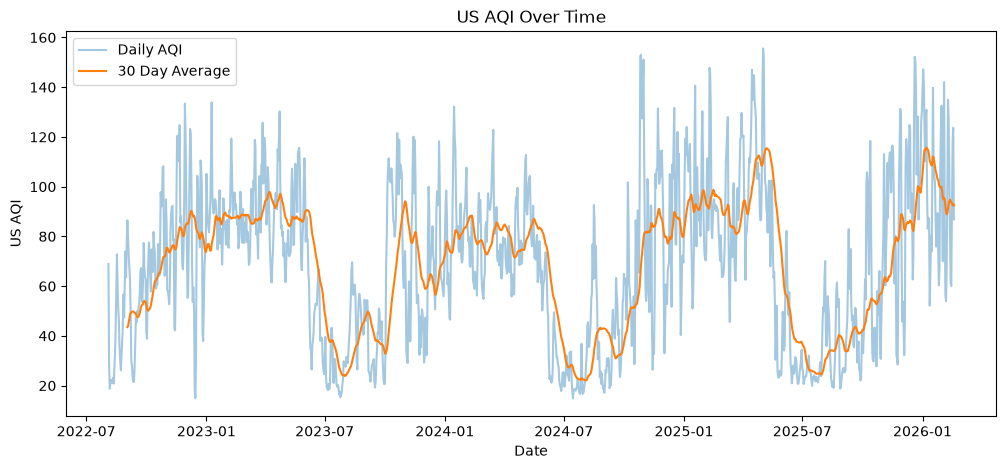

In [212]:
plt.figure(figsize=(12,5))
plt.plot(df["date"], df["us_aqi"] , alpha=0.4, label="Daily AQI")
plt.plot(df["date"], df["us_aqi"].rolling(30).mean(), label="30 Day Average")
plt.title("US AQI Over Time"); plt.ylabel("US AQI"); plt.xlabel("Date"); plt.legend(); 
plt.show()

This visual shows Daily AQI from August 2022 to Feb 2026, with a 30 day rolling average that smooths out day-to-day noise to reveal the long-run trend.

-> The 30-day average follows a repeating yearly cycle: it climbs to roughly 85-115 during the dry months and falls to about 22-40 around July each year.

-> The peaks after 2024 monsoon and during 2025-26 reach higher daily values than the earlier winters, which supports the rising-winter pattern.

**2.Stacked bar of Good , Moderate and Poor days (in %) for each year.**

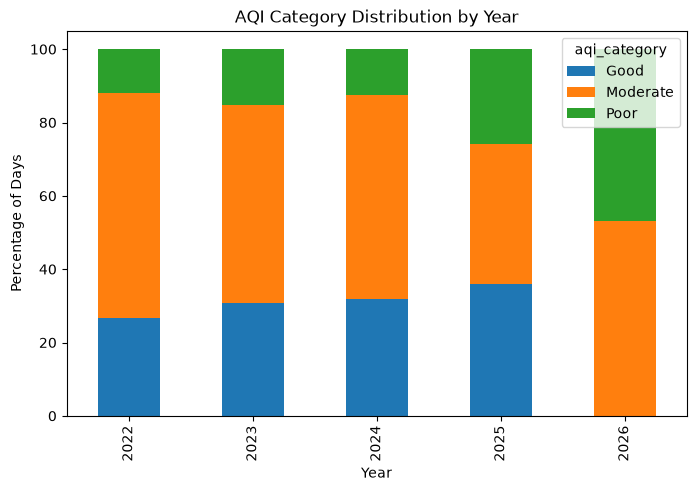

In [213]:
pd.crosstab(df["year"],df["aqi_category"],normalize='index').mul(100).plot(kind='bar', stacked=True, figsize =(8,5))
plt.title("AQI Category Distribution by Year"); plt.ylabel("Percentage of Days"); plt.xlabel("Year");
plt.show()

This visual shows the percentage of days falling into the Good(AQI <= 50), Moderate (51 - 100) and Poor(> 100) categories on a yearly basis.

-> Moderate is the largest category in every full year.

-> Years where the Poor share grows while the Good share also grows suggest more extreme swings between clean monsoon days and polluted dry-season days.

**3.Bar chart of average AQI by month to show seasonality.**

In [214]:
month_order = ["January","February","March","April","May","June",
               "July","August","September","October","November","December"]

monthly_aqi = df.groupby("month")["us_aqi"].mean().reindex(month_order)

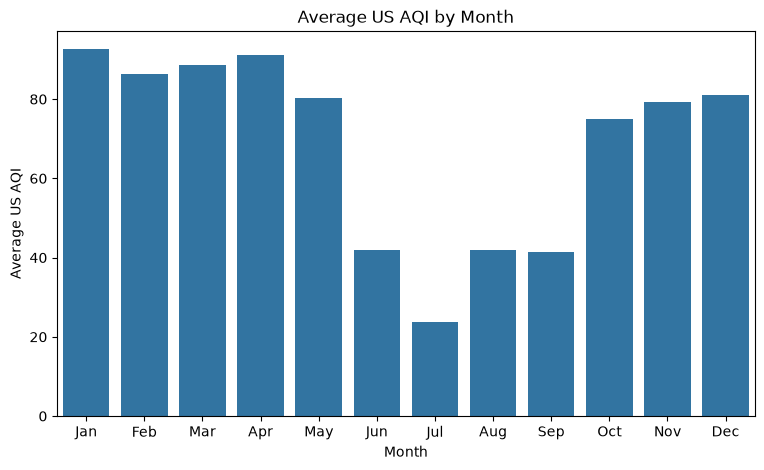

In [215]:
plt.figure(figsize=(9,5))
sns.barplot(x=month_names, y=monthly_aqi.values)
plt.title("Average US AQI by Month"); plt.ylabel("Average US AQI"); plt.xlabel("Month"); 
plt.show()   

This visual shows the average US AQI for each calendar month, used to find the best and worst months of the year.

-> January is the worst month (92.6) and July (23.9) is the best month.

-> Air quality roughly halves between May(80.4) and June(41.8) as the monsoon begins, and then deteriorates from September to October(41.3 to 74.9) as it retreats.

-> The elevated months run from October through May, with November and December slightly lower (about 79-81) than January - April.

**4. Heatmap of average AQI on year and season to show seasonality.**

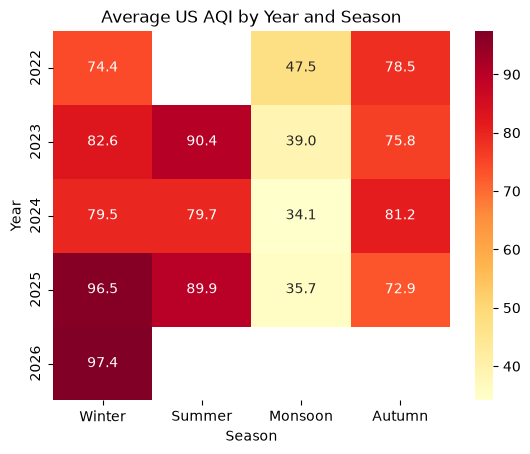

In [216]:
table = df.pivot_table(index='year', columns='season' ,values='us_aqi',aggfunc='mean')[season_order]
sns.heatmap(table, annot=True, fmt=".1f", cmap='YlOrRd')
plt.title("Average US AQI by Year and Season"); plt.ylabel("Year"); plt.xlabel("Season");
plt.show()

This visual shows a year-by-season grid of average US AQI, with darker colours marking worse air.

->  Monsoon is the lightest column every year so the cleanest season effect is consistent, while winter is the darkest and fastest-worsening row.

-> Summer is high and volatile , while autumn stays steadier.

**5. Barplot comparing AQI across seasons.**

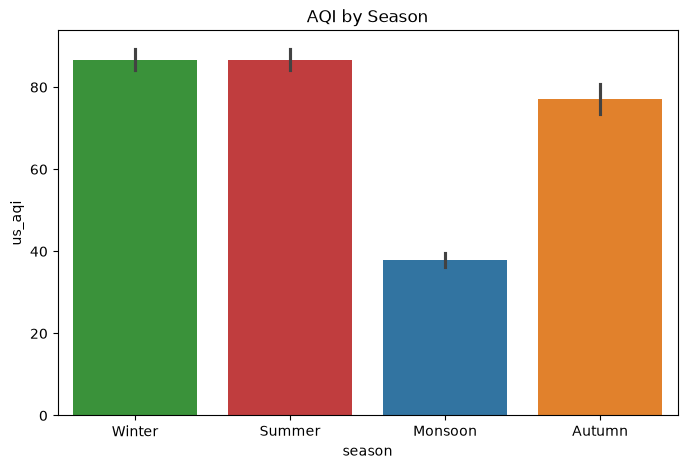

In [217]:
plt.figure(figsize=(8,5))
sns.barplot(data=df , x="season", y="us_aqi", order= season_order , hue= "season")
plt.title("AQI by Season")
plt.show()

This visual shows the mean US AQI for each season, with the small black line on each bar showing the uncertainty around the average.

-> Winter(86.7) and Summer(86.6) are nearly identical and the worst seasons , Autumn is somewhat better at 77.1.

-> Monsoon is far cleaner at 37.7, less than half the other seasons.

**6. Interactive scatter of PM2.5 vs PM10 by season.**

In [218]:
px.scatter(df, x="pm10", y="pm2_5", color="season", hover_data=["date", "us_aqi"], title="PM2.5 vs PM10").show()

This visual shows each day as a point, plotting fine particles (PM2.5) against coarser particles (PM10), coloured by season.

-> The relationship is almost linear (correlation about  0.94), and on average PM2.5 is roughly 0.72 times PM10.

-> Monsoon days cluster at the bottom-left (mean PM10 15.4 , PM2.5 9.5), while Winter , Summer and Autumn days spread to the top right (PM2.5 averages of 28.7, 26.6 and 25.1).

**7. Correlation heatmap of pollutants and AQI.**

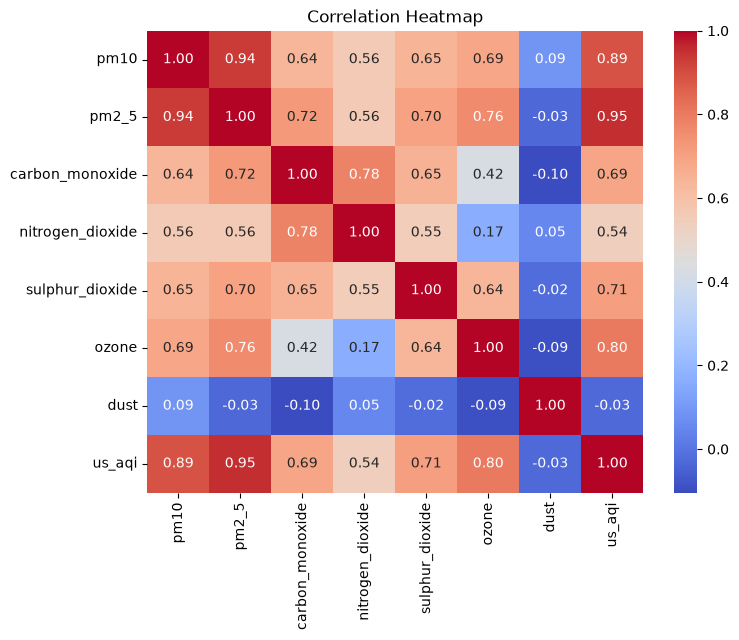

In [219]:
plt.figure(figsize=(8,6))
sns.heatmap(df[pollutants + ["us_aqi"]].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

This visual shows how strongly each pair of pollutants moves together, from -1(opposite) to +1(in step).

-> PM2.5 and PM10 are the strongest AQI drivers, followed by ozone ,sulphur dioxide and carbon monoxide 

-> Carbon monoxide and nitrogen dioxide move together strongly(0.78), which is consistent with a shared vehicle-exhaust and combustion source.


**8. Boxplot of the PM2.5/PM10 ratio by season.**

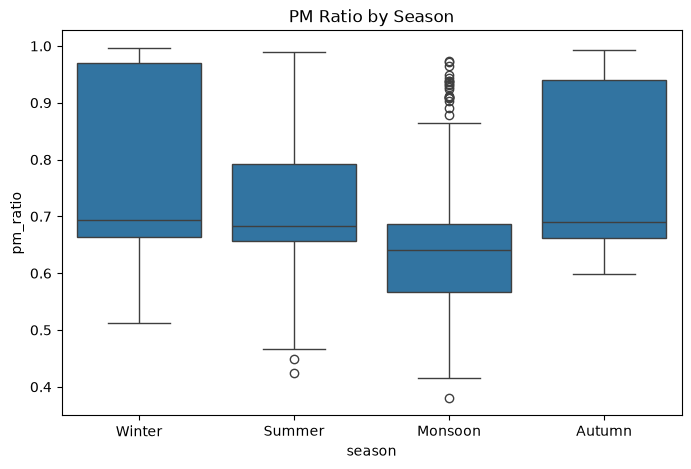

In [220]:
plt.figure(figsize=(8,5))
sns.boxplot(data= df ,x="season", y="pm_ratio", order=season_order)
plt.title("PM Ratio by Season")
plt.show()

This visual shows the spread of the PM2.5 to PM10 ratio in each season, where a high ratio means fine, combustion-type particles dominate and a low ratio means more coarse , dust-type particles.

-> The overall ratio averages 0.73, so fine particles make up most of the particulate load in every season.

-> Winter has the highest average ratio , with its upper quarter of days reaching about 0.97, which points to smoke , vehicle and other combustion sources.

-> Monsoon has the lowest ratio 0.64 and a few high outliers, which fits rain washing out fine particles while leaving relatively more coarse materials.

**9. Pie chart of the share of Good , Moderate and Poor air-quality days.**

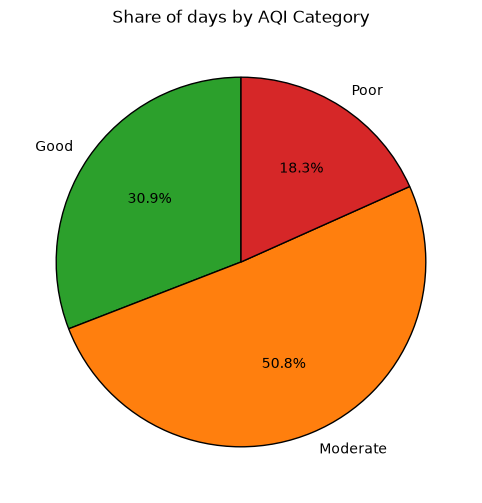

In [221]:
counts = df["aqi_category"].value_counts().reindex(['Good','Moderate','Poor']).dropna()
plt.figure(figsize=(6,6))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90, colors=['#2ca02c','#ff7f0e','#d62728'], wedgeprops={'edgecolor':'black'})
plt.title("Share of days by AQI Category")
plt.show()

This visual shows the proportion of all days with Good , Moderate and Poor air quality.

-> Nearly 7 in 10 days are Moderate or Poor , so clean air is the exception rather than the norm, even though extreme pollution is uncommon.

-> No day crosses AQI 156, so the data contains no severe or hazardous episodes.

**10. Histogram of daily PM2.5 with the WHO and Indian limits marked.**

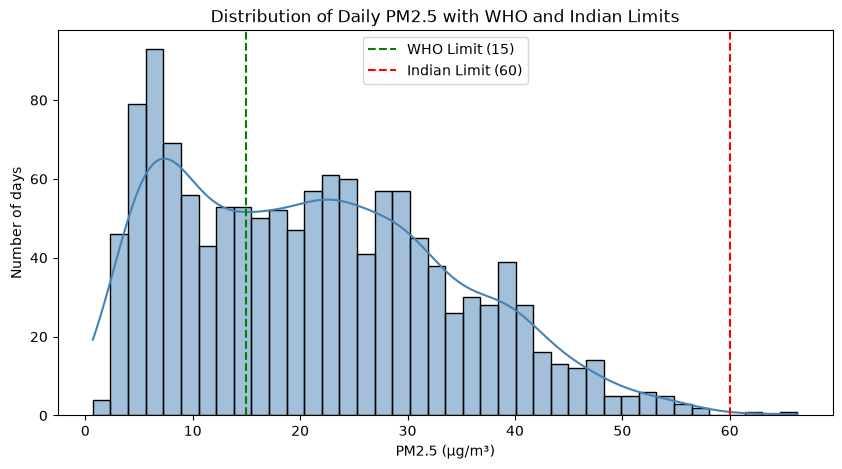

In [222]:
plt.figure(figsize=(10,5))
sns.histplot(df["pm2_5"],bins=40,kde=True,  color="steelblue")
plt.axvline(15, color="green", linestyle="--", label="WHO Limit (15)")
plt.axvline(60, color="red", linestyle="--", label="Indian Limit (60)")
plt.title("Distribution of Daily PM2.5 with WHO and Indian Limits"); 
plt.xlabel("PM2.5 (µg/m³)"); plt.ylabel("Number of days");
plt.legend();
plt.show()

This visual shows the proportion of all days with Good , Moderate and Poor air quality.

-> About 63% of days exceed the WHO guideline , so most days are above what the WHO considers safe.

-> Only about 0.2% of days cross the Indian limit, with the maximum at 66.3 , so Bengaluru is compliant by national standards but not by international health standards.

<h3 style="background-color:SkyBlue;">Insight Generation and Report</h3>

### KEY INSIGHTS

**1. Air quality is mostly "Moderate" and clean air is the exception.**

Of 1294 days with a US AQI value, 50.8% were Moderate (657 days), 30.9% Good (400 days) and 18.3% Poor (237 days). Nearly 7 in 10 days were Moderate or Poor. The average US AQI was 68.9.


**2. Seasonality is the strongest pattern in the data.**

The monsoon(Jun-Sep) is by far the cleanest season, with an average AQI of 37.7 and PM2.5 of 9.5 µg/m³.
Winter (86.7) and Summer (86.6) are the worst seasons, and Autumn is slightly better (77.1).
January is the worst month (92.6) and July the best (23.9).
AQI  roughly halves between May (80.4) and June (41.8) when the monsoon begins, then climbs from September (41.3) to October (74.9) as it retreats.



**3. Fine particles dominate, and PM2.5 is the main driver of the AQI**

PM2.5 (r = 0.95) and PM10 (r = 0.89) track the AQI most closely, followed by ozone (0.80), sulphur dioxide (0.71) and carbon monoxide (0.69). The PM2.5/PM10 ratio averages 0.73, so fine particles make up most of the particulate load. The ratio is highest in winter (0.81), which points to combustion sources such as vehicles and smoke. It is lowest in the monsoon (0.64), when rain washes out fine particles and leaves relatively more coarse material.

**4. Bengaluru meets Indian limits but not WHO guidelines.**
About 63% of days exceed the WHO 24-hour PM2.5 guideline (15 µg/m³), while only about 0.2% exceed the Indian limit (60 µg/m³). The maximum recorded PM2.5 was 66.3 µg/m³.


**5. Winter pollution appears to be worsening.**
Average winter AQI rose from 74.4 (2022) to 96.5 (2025). The 2026 winter value (97.4) covers only Jan–mid Feb, so it is not directly comparable with full seasons. Overall yearly averages (65–71 for 2022–2025) show no clear long-term trend, because the monsoon lowers the average each year.

**6. The worst days cluster around specific periods.**
The 10 worst days (AQI 147–156) fell in late April–early May, late October, late December and early January–February. Late October 2024 is close to the Diwali period, and December–January overlaps the winter and New Year period. These links are hypotheses and should be tested. No day reached a severe or hazardous level.

**7. Weekdays and weekends are almost the same.**
Average AQI was 69.1 on weekdays and 68.4 on weekends, so day-of-week traffic patterns are not a major factor in this dataset. CO and NO₂ move together strongly (0.78), which is consistent with a shared vehicle and combustion source.

### Recommendations

1. **Focus on PM2.5 first.** It drives the AQI more than any other pollutant, so control measures should target fine particles.
2. **Prepare for the high-risk months (October to May).** Public health advisories, especially for children, the elderly and people with respiratory conditions, should be issued before this period rather than after it begins.
3. **Tackle combustion sources.** The high winter PM ratio and the CO–NO₂ link support action on vehicle emissions, waste and biomass burning, and construction machinery.
4. **Plan for peak-risk events.** Review festival-period and year-end days for temporary measures such as emission checks and cracker regulations.
5. **Use WHO guidelines for health communication.** Compliance with national limits can hide the fact that most days exceed levels the WHO considers safe.
6. **Add an alert level for "Poor" days.** Use the 7-day PM2.5 average as an early-warning signal for building pollution episodes.


### Conclusion

This project analysed 1,295 days of air quality data for Bengaluru (August 2022 to February 2026). It shows that the city's air is rarely clean and rarely dangerous. Most days fall in the Moderate band, about 31% are Good and about 18% are Poor. No day reached a severe or hazardous level, and the highest AQI was about 156.

Three conclusions stand out:

1. **Season decides air quality.** The monsoon is the cleanest period (average AQI 37.7), while winter and summer are the worst (about 86.7 each). The pattern repeats every year, with January the worst month and July the best.
2. **Fine particles drive the pollution.** PM2.5 tracks the AQI most closely (r = 0.95). The high PM2.5/PM10 ratio in winter (0.81), together with the strong link between CO and NO₂ (0.78), points to combustion sources such as vehicles and smoke. Dust shows no relationship with the AQI.
3. **Compliance with national limits hides a health risk.** Only about 0.2% of days exceed the Indian PM2.5 limit, but about 63% exceed the WHO guideline. Bengaluru meets national standards but not international health standards.
